# 01 · Calidad de datos y preparación
**Proyecto:** StreamView Analytics · Visual Analytics para la Gerencia de Contenidos y Adquisición
**Objetivo del notebook:** revisar la calidad de los dos datasets oficiales, documentar cada problema encontrado y
justificar las transformaciones aplicadas en `src/prepare_data.py` (sección 15 del caso: *Calidad de los Datos*).

> Regla del caso: *no modificar la estructura original*. Los archivos de `data/raw/` no se tocan; todas las
> transformaciones generan copias en `data/processed/`.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import plotly.io as pio
pio.renderers.default = "png"          # imágenes estáticas: el notebook se ve igual en cualquier visor
pio.renderers["png"].width = 1100
pio.renderers["png"].scale = 1.5
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
import theme as T, charts as C
from data import load

## 1. Carga de las fuentes oficiales

In [2]:
movies = pd.read_csv(ROOT / "data/raw/movies_clean.csv")
tv = pd.read_csv(ROOT / "data/raw/tvshows_clean.csv")
pd.DataFrame({"Películas": [movies.shape[0], movies.shape[1]], "Series": [tv.shape[0], tv.shape[1]]},
             index=["Registros", "Variables"])

,Películas,Series
Registros,16000,16000
Variables,18,16


In [3]:
print("Variables solo en películas:", sorted(set(movies.columns) - set(tv.columns)))
movies.dtypes.to_frame("tipo_películas").join(tv.dtypes.to_frame("tipo_series"))

Variables solo en películas: ['budget', 'revenue']


,tipo_películas,tipo_series
show_id,int64,int64
type,str,str
title,str,str
director,str,str
cast,str,str
country,str,str
date_added,str,str
release_year,int64,int64
rating,float64,float64
duration,str,str


## 2. Valores nulos "disfrazados"
Los datasets no tienen `NaN` reales: los faltantes vienen codificados como el texto **"Sin información"**.
Contarlos como nulos es el primer paso para no tomar *"Sin información"* como si fuera un país o un director.

In [4]:
SI = "Sin información"
falt = pd.DataFrame({
    "Películas": (movies == SI).mean() * 100,
    "Series": (tv == SI).mean() * 100}).round(1)
falt[(falt > 0).any(axis=1)].sort_values("Series", ascending=False)

,Películas,Series
director,0.8,68.5
description,0.8,20.0
country,2.9,11.2
cast,1.3,7.2
genres,0.7,6.1
duration,100.0,0.0


**Lectura:** en series faltan director (69%), descripción (20%) y país (11%). Por eso los análisis de talento en
series y los de país se interpretan con cautela y se indica la limitación en cada visualización (regla de negocio 9).

## 3. Variables sin valor analítico

In [5]:
print("rating == vote_average en películas:", (movies.rating == movies.vote_average).mean())
print("rating == vote_average en series   :", (tv.rating == tv.vote_average).mean())
print("Valores únicos de duration (películas):", movies.duration.unique())
print("Valores únicos de duration (series)   :", tv.duration.unique())

rating == vote_average en películas: 1.0
rating == vote_average en series   : 1.0
Valores únicos de duration (películas): <ArrowStringArray>
['Sin información']
Length: 1, dtype: str
Valores únicos de duration (series)   : <ArrowStringArray>
['1 Seasons']
Length: 1, dtype: str


**Hallazgo crítico:** `rating`, que según el diccionario debería ser la *clasificación por edad* (TV-MA, PG-13…),
es en realidad una copia exacta de `vote_average` en el 100% de los registros. Y `duration` no tiene información
(películas) o es constante "1 Seasons" (series).

**Decisión:** ambas variables se excluyen. **Consecuencia:** los *KPIs de Clasificación* del caso (distribución
por clasificación etaria, popularidad y calificación por clasificación) **no pueden calcularse con estos datos**.
Se reporta como limitación y como oportunidad de mejora de la fuente (ver informe, evaluación crítica).

## 4. Duplicados y clave primaria

In [6]:
print("show_id duplicados en películas:", movies.show_id.duplicated().sum())
print("show_id duplicados en series   :", tv.show_id.duplicated().sum())
print("show_id repetidos ENTRE datasets:", len(set(movies.show_id) & set(tv.show_id)))
print("Filas idénticas:", movies.duplicated().sum(), tv.duplicated().sum())
print("Títulos homónimos (distinto show_id):", movies.title.duplicated().sum(), tv.title.duplicated().sum())

show_id duplicados en películas: 0
show_id duplicados en series   : 9
show_id repetidos ENTRE datasets: 397
Filas idénticas: 0 0
Títulos homónimos (distinto show_id): 515 332


No hay duplicados dentro de cada dataset, pero **397 `show_id` se repiten entre películas y series** (TMDB usa
espacios de ID separados). Al integrar ambas fuentes se crea la clave `uid = "M-"/"T-" + show_id`.
Los títulos homónimos son obras distintas (remakes, coincidencias) y se conservan (regla 1: cada registro es un contenido).

## 5. Estructura temporal: una muestra estratificada

In [7]:
pd.DataFrame({"Películas": movies.release_year.value_counts().sort_index(),
              "Series": tv.release_year.value_counts().sort_index()}).T

release_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Películas,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000
Series,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000


In [8]:
for n, d in [("Películas", movies), ("Series", tv)]:
    same = (pd.to_datetime(d.date_added).dt.year == d.release_year).mean()
    print(f"{n}: año de date_added = release_year en {same:.0%} de los casos")

Películas: año de date_added = release_year en 100% de los casos
Series: año de date_added = release_year en 100% de los casos


**Hallazgo:** hay **exactamente 1.000 títulos por año y tipo** (2010–2025): el extracto es una muestra estratificada.
Además `date_added` cae siempre en el mismo año de estreno.

**Decisión de diseño:** un gráfico de "cantidad de títulos por año" sería una línea plana *por construcción* y
podría inducir a error. Por eso la evolución del catálogo se analiza como **cambio en la composición** (áreas
apiladas al 100%) y **evolución de la calificación/popularidad**, no como volumen. `date_added` se usa solo para
estacionalidad mensual.

## 6. Votos y confiabilidad de la calificación

In [9]:
q = pd.DataFrame({n: d.vote_count.describe(percentiles=[.25, .5, .75, .9]) for n, d in [("Películas", movies), ("Series", tv)]}).round(0)
q.loc["% con 0 votos"] = [(movies.vote_count == 0).mean() * 100, (tv.vote_count == 0).mean() * 100]
q.loc["% con < 10 votos"] = [(movies.vote_count < 10).mean() * 100, (tv.vote_count < 10).mean() * 100]
q.round(1)

,Películas,Series
count,16000.0,16000.0
mean,719.0,107.0
std,2080.0,607.0
min,0.0,0.0
25%,53.0,1.0
50%,138.0,4.0
75%,422.0,30.0
90%,1519.0,167.0
max,37119.0,24664.0
% con 0 votos,5.6,23.0


La mediana de votos de las series es **4**. Un `vote_average` de 10 con 1 voto, o de 0 con 0 votos, no es una
valoración real. **Decisiones:**
1. La calificación se usa solo si `vote_count ≥ 10` (columna `nota`).
2. Para rankings de "mejor evaluados" se usa una **calificación ponderada bayesiana** (fórmula tipo IMDb,
   m = 100 votos), que acerca a la media los títulos con pocos votos y evita que un 10/10 con 12 votos encabece la lista.

## 7. Popularidad: asimetría extrema

In [10]:
pd.DataFrame({n: d.popularity.describe(percentiles=[.5, .9, .99]) for n, d in [("Películas", movies), ("Series", tv)]}).round(1)

,Películas,Series
count,16000.0,16000.0
mean,20.4,64.9
std,68.6,139.4
min,3.9,2.3
50%,10.9,36.2
90%,33.2,118.5
99%,144.5,467.7
max,3876.0,6421.9


La media es 2–3 veces la mediana y el máximo es cientos de veces la mediana. **Decisiones:** usar **mediana**,
**percentiles dentro de cada tipo** (así una película y una serie se comparan en su propia escala, regla 2) y
**escala logarítmica** en los gráficos. Recordatorio (regla 5): popularidad es un índice relativo, no reproducciones.

## 8. Presupuesto e ingresos (solo películas)

In [11]:
b, r = movies.budget, movies.revenue
pd.Series({
    "budget = 0": (b == 0).sum(), "revenue = 0": (r == 0).sum(),
    "0 < budget < 100.000 (sospechoso)": ((b > 0) & (b < 1e5)).sum(),
    "Universo válido (budget ≥ 100k y revenue > 0)": ((b >= 1e5) & (r > 0)).sum()}).to_frame("películas")

,películas
budget = 0,11153
revenue = 0,10355
0 < budget < 100.000 (sospechoso),167
Universo válido (budget ≥ 100k y revenue > 0),3500


In [12]:
m = movies[(b > 0) & (r > 0)].assign(roi=lambda x: x.revenue / x.budget)
m.nlargest(5, "roi")[["title", "release_year", "budget", "revenue", "roi"]]

,title,release_year,budget,revenue,roi
6269,The Beatles: Eight Days a Week - The Touring Y...,2016,5,12283800,2.456760e+06
13648,No Dogs or Italians Allowed,2023,5,1395922,2.791844e+05
13935,Scrapper,2023,84,1234483,1.469623e+04
12594,The Good Neighbor,2022,105,94909,9.038952e+02
8803,Animal World,2018,125000,69885700,5.590856e+02


Existen presupuestos de USD 1–7.000 con ingresos de cientos de millones (ROI de 2.400.000x): son **errores de
registro** (cifras en millones cargadas como unidades). **Decisión (reglas 3 y 6):** indicadores financieros
solo con `budget ≥ USD 100.000` y `revenue > 0` → **3.500 películas**. Se usa el **ROI mediano** (no la media),
robusto a los éxitos extremos.

## 9. Taxonomías de género distintas

In [13]:
gm = movies.genres[movies.genres != SI].str.split(", ").explode().value_counts()
gt = tv.genres[tv.genres != SI].str.split(", ").explode().value_counts()
print("Solo en películas:", sorted(set(gm.index) - set(gt.index)))
print("Solo en series   :", sorted(set(gt.index) - set(gm.index)))

Solo en películas: ['Action', 'Adventure', 'Fantasy', 'History', 'Horror', 'Music', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War']
Solo en series   : ['Action & Adventure', 'Kids', 'News', 'Reality', 'Sci-Fi & Fantasy', 'Soap', 'Talk', 'Unknown', 'War & Politics']


Películas usa "Action", "Adventure", "Science Fiction"; series usa "Action & Adventure", "Sci-Fi & Fantasy".
Para comparar ambos tipos **solo cuando la variable es equivalente (regla 2)** se crea una **taxonomía armonizada
en español** (p. ej. *Acción y aventura*, *Ciencia ficción y fantasía*). Además se traducen idiomas (códigos ISO)
y países, porque la audiencia es la Gerencia de Contenidos hispanohablante.

## 10. Ejecución de la preparación y resultado

In [14]:
import prepare_data
prepare_data.main()
D = load()
print({k: v.shape for k, v in D.items()})
D["cat"][["uid", "tipo", "title", "release_year", "genero_principal", "pais_principal", "idioma",
          "popularity", "pct_popularidad", "nota", "nota_ponderada", "roi"]].head()

Catálogo unificado: 32,000 títulos (16,000 películas, 16,000 series)
Con valoración válida (>= 10 votos): 20,331
Universo financiero válido: 3,500 películas
Archivos escritos en C:\Users\alons\Desktop\StreamView EV3\data\processed


{'cat': (32000, 36), 'gen': (64777, 20), 'pais': (37636, 22), 'pers': (165167, 8), 'calidad': (32, 5)}


,uid,tipo,title,release_year,genero_principal,pais_principal,idioma,popularity,pct_popularidad,nota,nota_ponderada,roi
0,M-10192,Película,Shrek Forever After,2010,Comedia,Estados Unidos,Inglés,203.893,0.994125,6.380,6.379568,4.561217
1,M-27205,Película,Inception,2010,Acción y aventura,Reino Unido,Inglés,156.242,0.990938,8.369,8.363568,5.243941
2,M-12444,Película,Harry Potter and the Deathly Hallows: Part 1,2010,Acción y aventura,Reino Unido,Inglés,121.191,0.987125,7.744,7.736811,3.817223
3,M-38757,Película,Tangled,2010,Animación,Estados Unidos,Inglés,111.762,0.984750,7.600,7.589329,2.278699
4,M-10191,Película,How to Train Your Dragon,2010,Ciencia ficción y fantasía,Estados Unidos,Inglés,110.044,0.984250,7.800,7.789127,2.999270


In [15]:
D["calidad"]

,dataset,variable,hallazgo,registros,proporcion
0,Películas,director,Valor 'Sin información',132.0,0.008250
1,Películas,cast,Valor 'Sin información',204.0,0.012750
2,Películas,country,Valor 'Sin información',466.0,0.029125
3,Películas,duration,Valor 'Sin información',16000.0,1.000000
4,Películas,genres,Valor 'Sin información',107.0,0.006687
5,Películas,description,Valor 'Sin información',132.0,0.008250
6,Películas,rating,Idéntica a vote_average (no es clasificación e...,16000.0,1.000000
7,Películas,vote_count,Títulos con 0 votos (vote_average=0 no es una ...,894.0,0.055875
8,Películas,vote_count,Títulos con < 10 votos (valoración poco confia...,1817.0,0.113562
9,Películas,release_year,Muestra estratificada: exactamente 1.000 títul...,1.0,NaN


## 11. Resumen visual de calidad

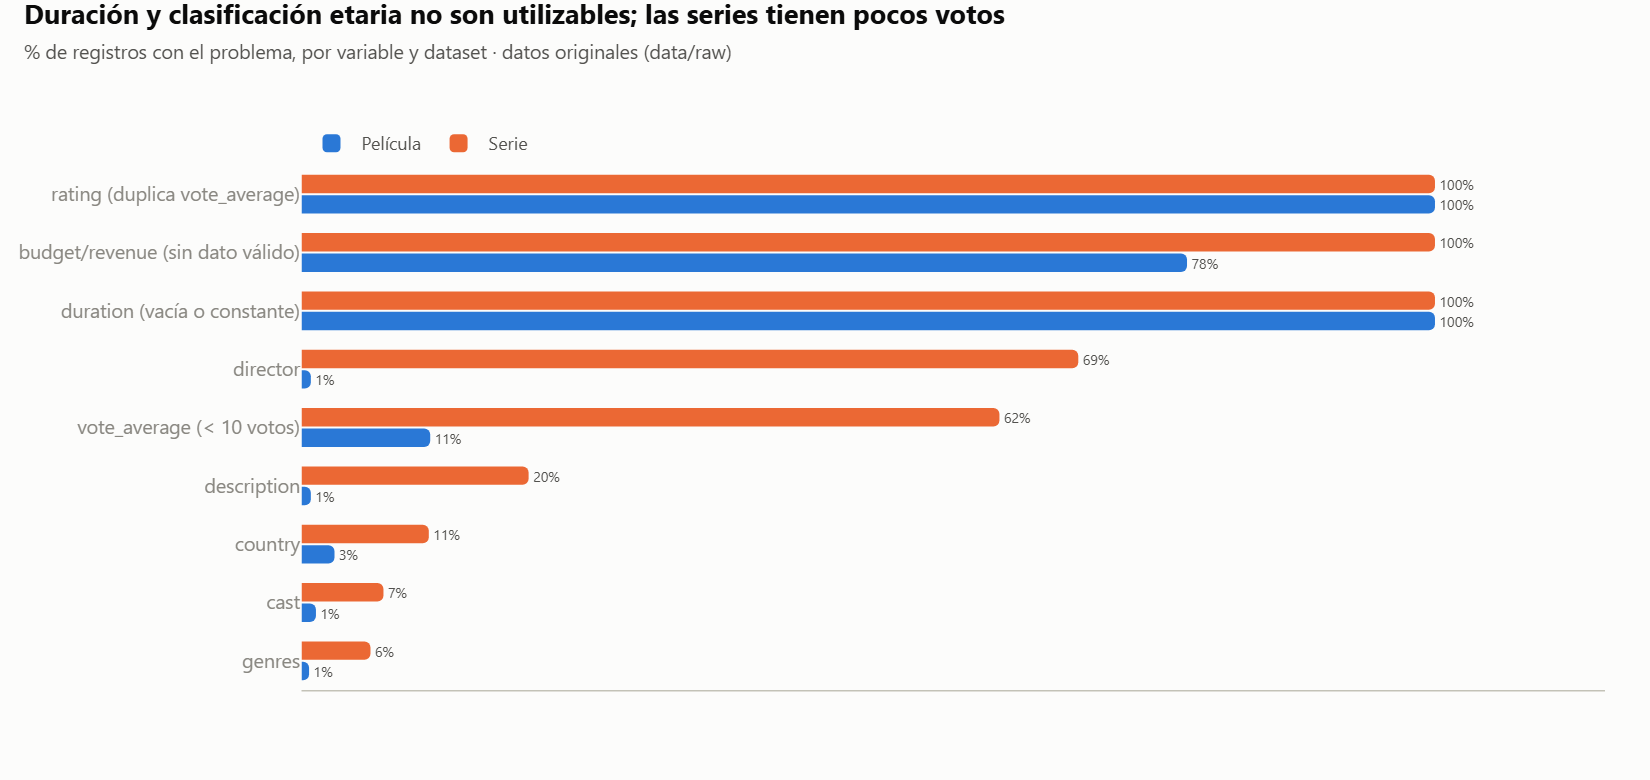

In [16]:
C.fig_calidad(movies, tv).show()

### Bitácora de transformaciones
| # | Transformación | Justificación |
|---|---|---|
| 1 | "Sin información" → nulo | Evita categorías falsas en gráficos de país, director, género |
| 2 | Clave `uid` = tipo + `show_id` | 397 IDs repetidos entre datasets |
| 3 | Se excluyen `rating` y `duration` | Duplicada / vacía o constante |
| 4 | `nota` = `vote_average` con ≥ 10 votos; `nota_ponderada` bayesiana | Confiabilidad de la valoración |
| 5 | `pct_popularidad` (percentil dentro del tipo) y log10 | Asimetría; comparabilidad película/serie |
| 6 | Universo financiero: budget ≥ 100k y revenue > 0; ROI, ganancia, tramos | Reglas 3 y 6; errores de registro |
| 7 | Taxonomía de géneros armonizada en español; idiomas y países traducidos | Regla 2; audiencia |
| 8 | Tablas "explotadas" de géneros, países y personas | Campos multivalor ("Drama, Romance") |